In [1]:
# Cài đặt unrar nếu chưa có
!apt-get install unrar

# Giải nén file vào thư mục hiện tại (/content/)
!unrar x skin-disease-datasaet.rar /content/

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.

UNRAR 7.00 freeware      Copyright (c) 1993-2024 Alexander Roshal


Extracting from skin-disease-datasaet.rar

Creating    /content/skin-disease-datasaet                            OK
Creating    /content/skin-disease-datasaet/test_set                   OK
Creating    /content/skin-disease-datasaet/test_set/BA- cellulitis    OK
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (1).webp       0%  OK 
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (104).jpg       0%  OK 
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (106).jpg       0%  OK 
Extracting  /content/skin-disease-datasaet/test_set/BA- cellulitis/BA- cellulitis (115).jpg       0%

In [3]:
# 1. Tạo thư mục có tên tương ứng (ví dụ: output_pseudo_masks_HSV_SAM)
import os
output_folder = '/content/output_pseudo_masks_HSV_SAM'
os.makedirs(output_folder, exist_ok=True)

# 2. Giải nén file .zip trực tiếp vào thư mục vừa tạo
!unzip -o output_pseudo_masks_HSV_SAM.zip -d {output_folder}

Archive:  output_pseudo_masks_HSV_SAM.zip
   creating: /content/output_pseudo_masks_HSV_SAM/BA- cellulitis/
   creating: /content/output_pseudo_masks_HSV_SAM/BA-impetigo/
   creating: /content/output_pseudo_masks_HSV_SAM/FU-athlete-foot/
   creating: /content/output_pseudo_masks_HSV_SAM/FU-nail-fungus/
   creating: /content/output_pseudo_masks_HSV_SAM/FU-ringworm/
   creating: /content/output_pseudo_masks_HSV_SAM/PA-cutaneous-larva-migrans/
   creating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/
   creating: /content/output_pseudo_masks_HSV_SAM/VI-shingles/
  inflating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/167_VI-chickenpox (12)_mask.png  
  inflating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/18_VI-chickenpox (1)_mask.png  
  inflating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/68_VI-chickenpox (3)_mask.png  
  inflating: /content/output_pseudo_masks_HSV_SAM/VI-chickenpox/22_VI-chickenpox (24)_mask.png  
  inflating: /content/output_pseudo_mask

In [ ]:
import os
import shutil

# Danh sách các thư mục bạn muốn xóa
folders = ['PA-cutaneous-larva-migrans', 'VI-chickenpox', 'VI-shingles'] # Thêm tên các thư mục vào đây

for folder in folders:
    folder_path = os.path.join('/content', folder)
    if os.path.exists(folder_path):
        shutil.rmtree(folder_path)
        print(f"Đã xóa: {folder}")

print("Đã dọn dẹp xong!")

In [2]:
import os
import cv2
import random
import matplotlib.pyplot as plt
from glob import glob
import numpy as np
from fontTools.misc.cython import returns
from tqdm import tqdm
import keras.backend as K
import time
import random
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.layers import SeparableConv2D, BatchNormalization, Activation
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D,Add, MaxPooling2D, Conv2DTranspose, concatenate,DepthwiseConv2D
from tensorflow.keras.optimizers import Adam

In [4]:
# ===============================
# CẤU HÌNH
# ===============================
DATA_DIR = '/content/skin-disease-datasaet/train_set'  # ảnh gốc
MASK_DIR = '/content/output_pseudo_masks_HSV_SAM'      # mask đã tạo HSV + SAM
LABELS = [
    "BA- cellulitis", "BA-impetigo", "FU-athlete-foot", "FU-nail-fungus",
    "FU-ringworm", "PA-cutaneous-larva-migrans", "VI-chickenpox", "VI-shingles"
]

In [5]:
# ===============================
# 🎯 LẤY NGẪU NHIÊN 1 ẢNH MỖI CLASS
# ===============================
sample_per_class = {}
for label in LABELS:
    class_dir = os.path.join(DATA_DIR, label)
    if not os.path.isdir(class_dir):
        print(f"⚠️ Không tìm thấy thư mục: {class_dir}")
        continue

    image_files = glob(os.path.join(class_dir, "**", "*.*"), recursive=True)
    image_files = [f for f in image_files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if not image_files:
        continue

    chosen_path = random.choice(image_files)
    sample_per_class[label] = chosen_path

print(f"✅ Đã chọn {len(sample_per_class)} ảnh đại diện cho các lớp.")

✅ Đã chọn 8 ảnh đại diện cho các lớp.


✅ Đã chọn 8 ảnh đại diện để hiển thị.


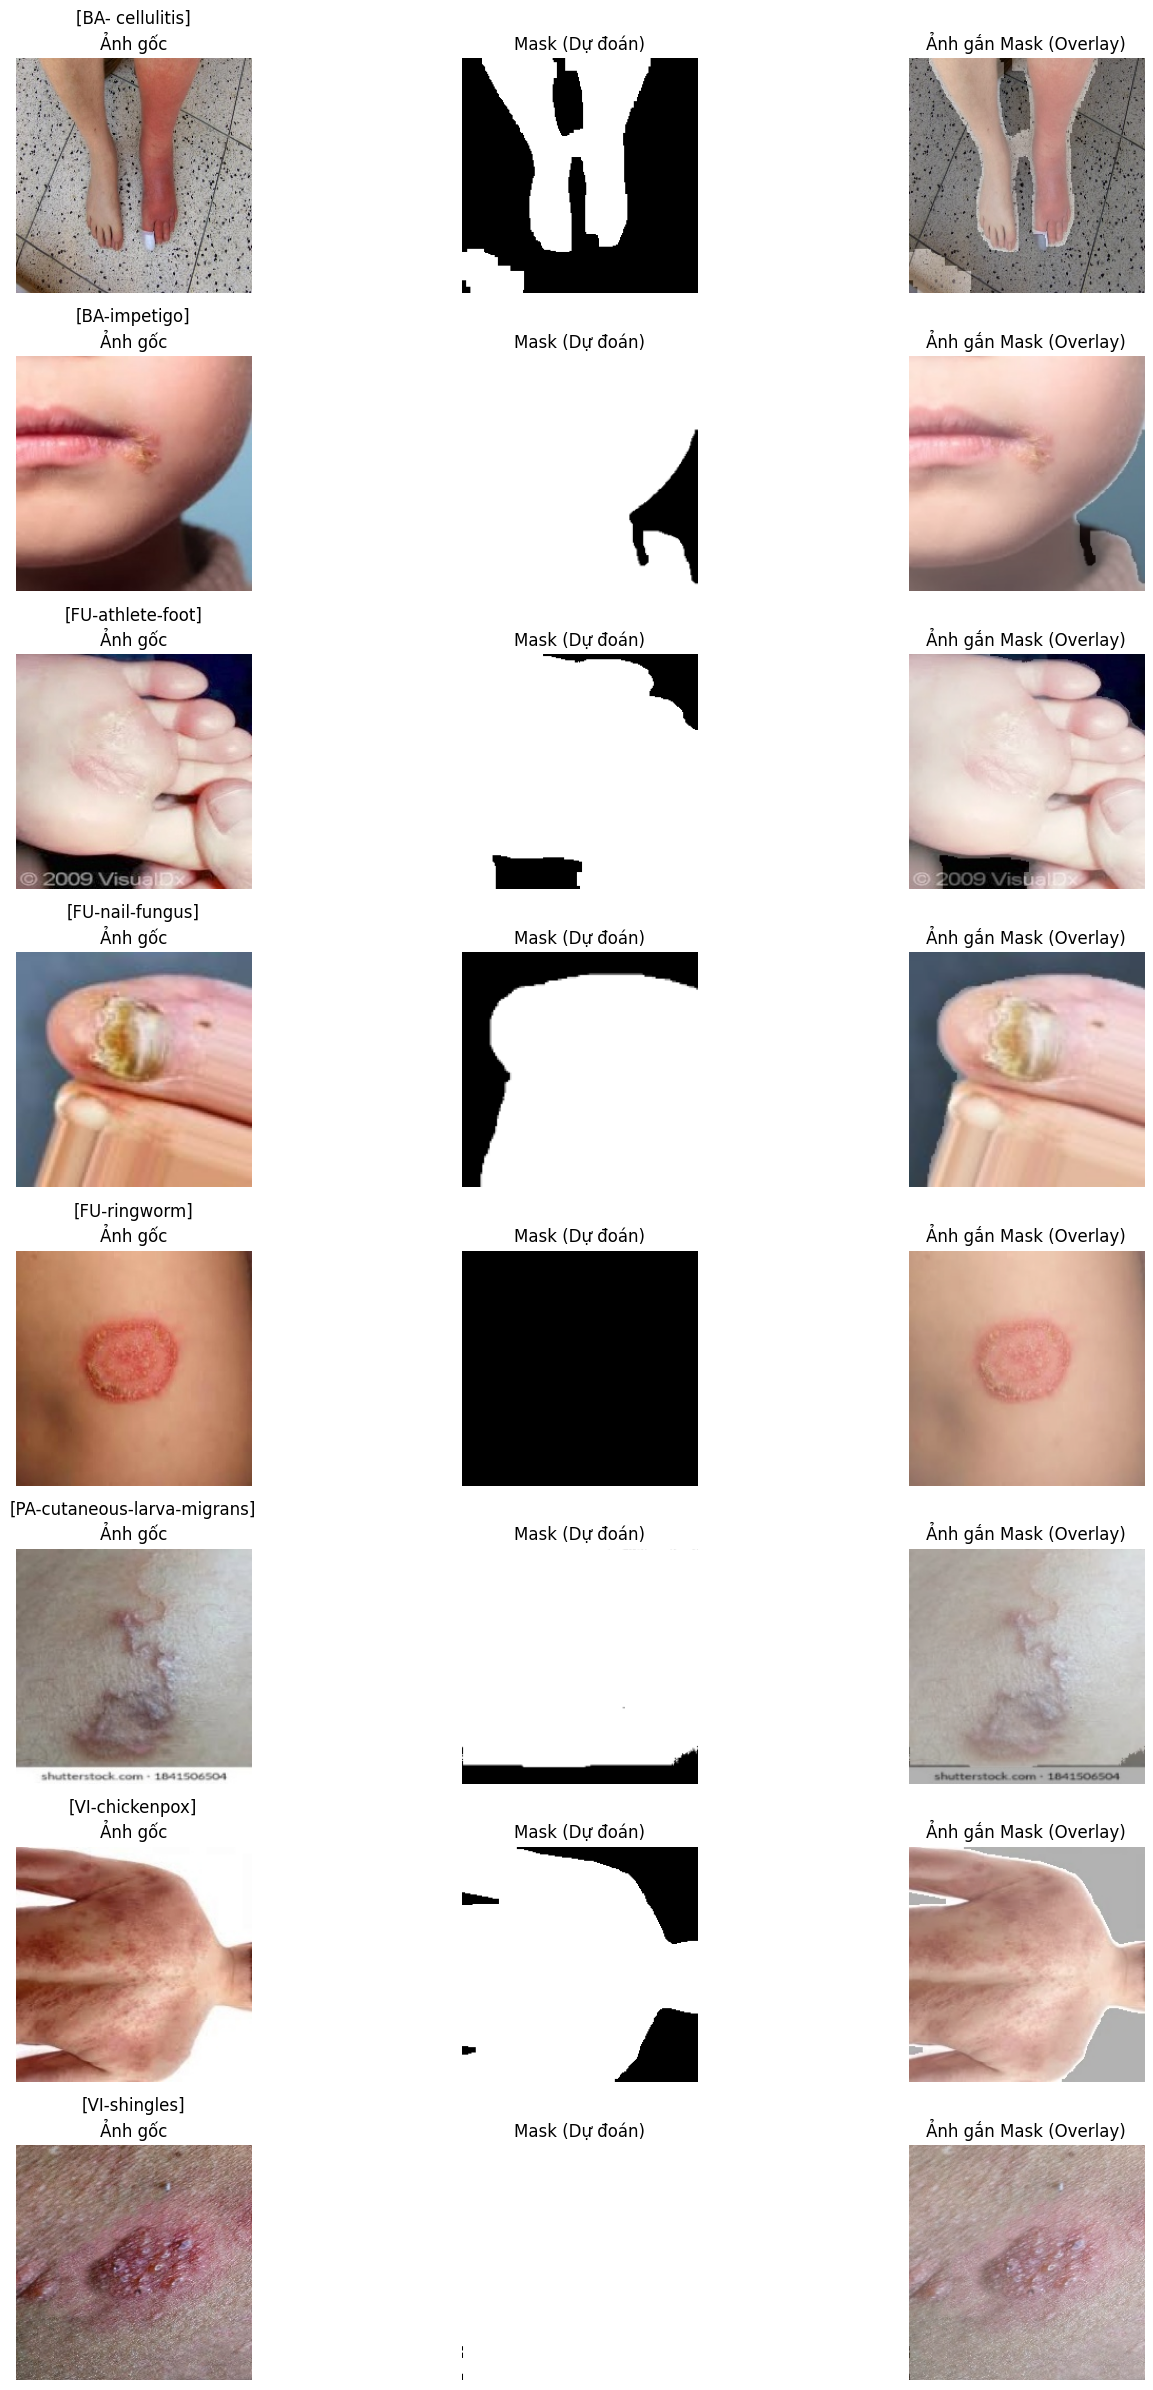

In [6]:
# ===============================
# 🎯 LẤY NGẪU NHIÊN 1 ẢNH MỖI CLASS ĐỂ VIEW
# ===============================
sample_per_class = {}
for label in LABELS:
    class_dir = os.path.join(DATA_DIR, label)
    if not os.path.isdir(class_dir):
        continue

    image_files = glob(os.path.join(class_dir, "**", "*.*"), recursive=True)
    image_files = [f for f in image_files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if not image_files:
        continue

    chosen_path = random.choice(image_files)
    sample_per_class[label] = chosen_path

print(f"✅ Đã chọn {len(sample_per_class)} ảnh đại diện để hiển thị.")

# ===============================
# 🖼️ HIỂN THỊ: ẢNH GỐC | MASK | OVERLAY
# ===============================
plt.figure(figsize=(15, len(sample_per_class) * 3))

for i, (class_name, img_path) in enumerate(sample_per_class.items()):
    # 1. Đọc ảnh gốc
    img = cv2.imread(img_path)
    if img is None:
        continue
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 2. Tìm file mask tương ứng
    img_name = os.path.splitext(os.path.basename(img_path))[0]
    # Lưu ý cách đặt tên file mask lúc lưu (_mask.png)
    mask_path = os.path.join(MASK_DIR, class_name, f"{img_name}_mask.png")

    if not os.path.exists(mask_path):
        print(f"⚠️ Không tìm thấy mask cho: {img_name}")
        continue

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    # Đảm bảo kích thước ảnh gốc và mask khớp nhau
    if mask.shape[:2] != img_rgb.shape[:2]:
        mask = cv2.resize(mask, (img_rgb.shape[1], img_rgb.shape[0]))

    # Chuyển mask sang RGB để làm hiệu ứng chồng (overlay)
    mask_rgb = cv2.cvtColor(mask, cv2.COLOR_GRAY2RGB)

    # Tạo ảnh chồng mask (Overlay): 70% ảnh gốc + 30% mask
    overlay = cv2.addWeighted(img_rgb, 0.7, mask_rgb, 0.3, 0)

    # --- Vẽ lên biểu đồ ---
    # Cột 1: Ảnh gốc
    plt.subplot(len(sample_per_class), 3, i * 3 + 1)
    plt.imshow(img_rgb)
    plt.title(f"[{class_name}]\nẢnh gốc")
    plt.axis("off")

    # Cột 2: Mask trắng đen
    plt.subplot(len(sample_per_class), 3, i * 3 + 2)
    plt.imshow(mask, cmap='gray')
    plt.title("Mask (Dự đoán)")
    plt.axis("off")

    # Cột 3: Ảnh đã được gắn mask (Overlay)
    plt.subplot(len(sample_per_class), 3, i * 3 + 3)
    plt.imshow(overlay)
    plt.title("Ảnh gắn Mask (Overlay)")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# HÀM ĐÁNH GIÁ (METRICS)
# ============================================================
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)


def iou_score(y_true, y_pred, smooth=1e-6):
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

In [8]:
IMAGE_SIZE = 128

def load_dataset(image_dir, mask_dir, image_size=IMAGE_SIZE):
    X, Y = [], []
    all_images = glob(os.path.join(image_dir, "*", "*.*"))
    all_images = [f for f in all_images if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    for path in tqdm(all_images, desc="Đang tải dataset"):
        try:
            # 1. Xác định tên lớp và tên file mask trước
            class_name = os.path.basename(os.path.dirname(path))
            img_name = os.path.splitext(os.path.basename(path))[0]
            mask_path = os.path.join(mask_dir, class_name, f"{img_name}_mask.png")

            # 2. Kiểm tra nếu mask không tồn tại thì bỏ qua ngay (tránh lệch mảng X và Y)
            if not os.path.exists(mask_path):
                continue

            # 3. Đọc ảnh gốc
            img = cv2.imread(path)
            if img is None:
                continue

            # 4. Đọc mask
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            if mask is None:
                continue

            # 5. Resize và chuẩn hóa đồng bộ
            img = cv2.resize(img, (image_size, image_size)) / 255.0
            mask = cv2.resize(mask, (image_size, image_size)) / 255.0
            mask = np.expand_dims(mask, axis=-1)

            # 6. Chỉ append khi cả ảnh và mask đều hợp lệ
            X.append(img)
            Y.append(mask)

        except Exception as e:
            print(f"Lỗi khi xử lý {path}: {e}")
            continue

    return np.array(X), np.array(Y)

# Gọi lại hàm load sau khi đã sửa
X, Y = load_dataset(DATA_DIR, MASK_DIR) # Lưu ý trỏ đúng tên thư mục mask của bạn
print(f"✅ Dataset hoàn tất: X shape: {X.shape}, Y shape: {Y.shape}")

Đang tải dataset: 100%|██████████| 924/924 [00:01<00:00, 715.99it/s]


✅ Dataset hoàn tất: X shape: (856, 128, 128, 3), Y shape: (856, 128, 128, 1)


In [10]:
# ==================================================
# ✂️ Chia dữ liệu Train / Validation
# ==================================================
from sklearn.model_selection import train_test_split

X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size=0.2, random_state=42)
print(f"Train: {X_train.shape}, Val: {X_val.shape}")


Train: (684, 128, 128, 3), Val: (172, 128, 128, 3)


In [14]:
# ==================================================
# XÂY DỰNG MÔ HÌNH
# ==================================================
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, Add, MaxPooling2D, Conv2DTranspose,
    concatenate, DepthwiseConv2D, UpSampling2D, Activation, Multiply
)
from tensorflow.keras.optimizers import Adam


# --- 2. MobileNet U2-UNet ---
from tensorflow.keras.applications import MobileNetV2

def mobilenet_u2_unet(input_size=(128, 128, 3)):
    inputs = Input(input_size)
    base_model = MobileNetV2(input_tensor=inputs, include_top=False, weights='imagenet')

    # Các tầng skip từ MobileNetV2
    skip_names = ["block_1_expand_relu", "block_3_expand_relu", "block_6_expand_relu", "block_13_expand_relu"]
    skips = [base_model.get_layer(name).output for name in skip_names]

    x = base_model.output

    # Decoder: 4 tầng upsampling
    for i, skip in enumerate(reversed(skips)):
        x = UpSampling2D((2, 2))(x)
        x = Conv2D(256 // (2 ** i), 3, padding='same', activation='relu')(x)
        x = concatenate([x, skip])
        x = Conv2D(256 // (2 ** i), 3, padding='same', activation='relu')(x)

    # Thêm bước upsample cuối cùng để lên (128x128)
    x = UpSampling2D((2, 2))(x)

    outputs = Conv2D(1, 1, activation='sigmoid')(x)
    return Model(inputs, outputs, name="MobileNet-U2-UNet")


# --- 3. Attention UNet ---
def attention_block(x, g, inter_channel):
    theta_x = Conv2D(inter_channel, 1, padding='same')(x)
    phi_g = Conv2D(inter_channel, 1, padding='same')(g)
    add_xg = Add()([theta_x, phi_g])
    act = Activation('relu')(add_xg)
    psi = Conv2D(1, 1, padding='same')(act)
    psi = Activation('sigmoid')(psi)
    return Multiply()([x, psi])


def attention_unet(input_size=(128, 128, 3)):
    inputs = Input(input_size)
    c1 = Conv2D(32, 3, padding='same', activation='relu')(inputs)
    c1 = Conv2D(32, 3, padding='same', activation='relu')(c1)
    p1 = MaxPooling2D()(c1)
    c2 = Conv2D(64, 3, padding='same', activation='relu')(p1)
    c2 = Conv2D(64, 3, padding='same', activation='relu')(c2)
    p2 = MaxPooling2D()(c2)
    c3 = Conv2D(128, 3, padding='same', activation='relu')(p2)
    c3 = Conv2D(128, 3, padding='same', activation='relu')(c3)
    p3 = MaxPooling2D()(c3)
    bn = Conv2D(256, 3, padding='same', activation='relu')(p3)
    bn = Conv2D(256, 3, padding='same', activation='relu')(bn)
    u3 = UpSampling2D()(bn)
    a3 = attention_block(c3, u3, 128)
    u3 = concatenate([u3, a3])
    u3 = Conv2D(128, 3, padding='same', activation='relu')(u3)
    u2 = UpSampling2D()(u3)
    a2 = attention_block(c2, u2, 64)
    u2 = concatenate([u2, a2])
    u2 = Conv2D(64, 3, padding='same', activation='relu')(u2)
    u1 = UpSampling2D()(u2)
    a1 = attention_block(c1, u1, 32)
    u1 = concatenate([u1, a1])
    u1 = Conv2D(32, 3, padding='same', activation='relu')(u1)
    outputs = Conv2D(1, 1, activation='sigmoid')(u1)
    return Model(inputs, outputs, name="Attention-UNet")


# --- Khởi tạo mô hình (Chọn 1 trong 2 mô hình bạn muốn dùng) ---
# Cách 1: Dùng mô hình MobileNet U2-UNet
model = mobilenet_u2_unet(input_size=(128, 128, 3))

# Cách 2: Hoặc dùng mô hình Attention UNet
# model = attention_unet(input_size=(128, 128, 3))

model.summary()

/tmp/ipykernel_1574/678422936.py:17: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_tensor=inputs, include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNet-U2-UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 8,037,409 (30.66 MB)

 Trainable params: 8,003,297 (30.53 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [15]:
# ==================================================
# ⚙️ COMPILE MÔ HÌNH
# ==================================================
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)


In [16]:
# ==================================================
# TRAIN MÔ HÌNH + THỜI GIAN
# ==================================================
import time

# Khai báo giá trị cho các biến trước khi sử dụng
EPOCHS = 30
BATCH_SIZE = 8

print(f"⏳ Bắt đầu huấn luyện: Epochs={EPOCHS}, Batch_size={BATCH_SIZE}")
start_time = time.time()

history = model.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

end_time = time.time()
train_time = end_time - start_time
print(f"✅ Hoàn tất huấn luyện trong {train_time:.2f} giây ({train_time/60:.2f} phút)")

⏳ Bắt đầu huấn luyện: Epochs=30, Batch_size=8
Epoch 1/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 168s 880ms/step - accuracy: 0.8318 - loss: 0.3881 - val_accuracy: 0.8278 - val_loss: 0.4970
Epoch 2/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9002 - loss: 0.2468 - val_accuracy: 0.8241 - val_loss: 0.5782
Epoch 3/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9206 - loss: 0.2030 - val_accuracy: 0.8228 - val_loss: 0.6966
Epoch 4/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9316 - loss: 0.1717 - val_accuracy: 0.8185 - val_loss: 0.6969
Epoch 5/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9373 - loss: 0.1574 - val_accuracy: 0.8304 - val_loss: 0.6293
Epoch 6/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.9397 - loss: 0.1500 - val_accuracy: 0.8198 - val_loss: 0.7760
Epoch 7/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9424 - loss: 0.1387 - val_accuracy: 0.8205 - val_loss: 0.8747
Epoch 8/30
86/86 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy:

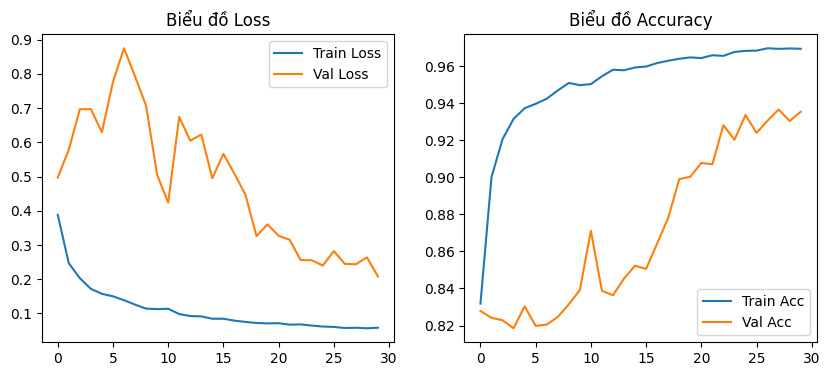

In [17]:
# ==================================================
# 📊 VẼ ĐỒ THỊ LOSS / ACCURACY
# ==================================================
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Biểu đồ Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Biểu đồ Accuracy')
plt.legend()

plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


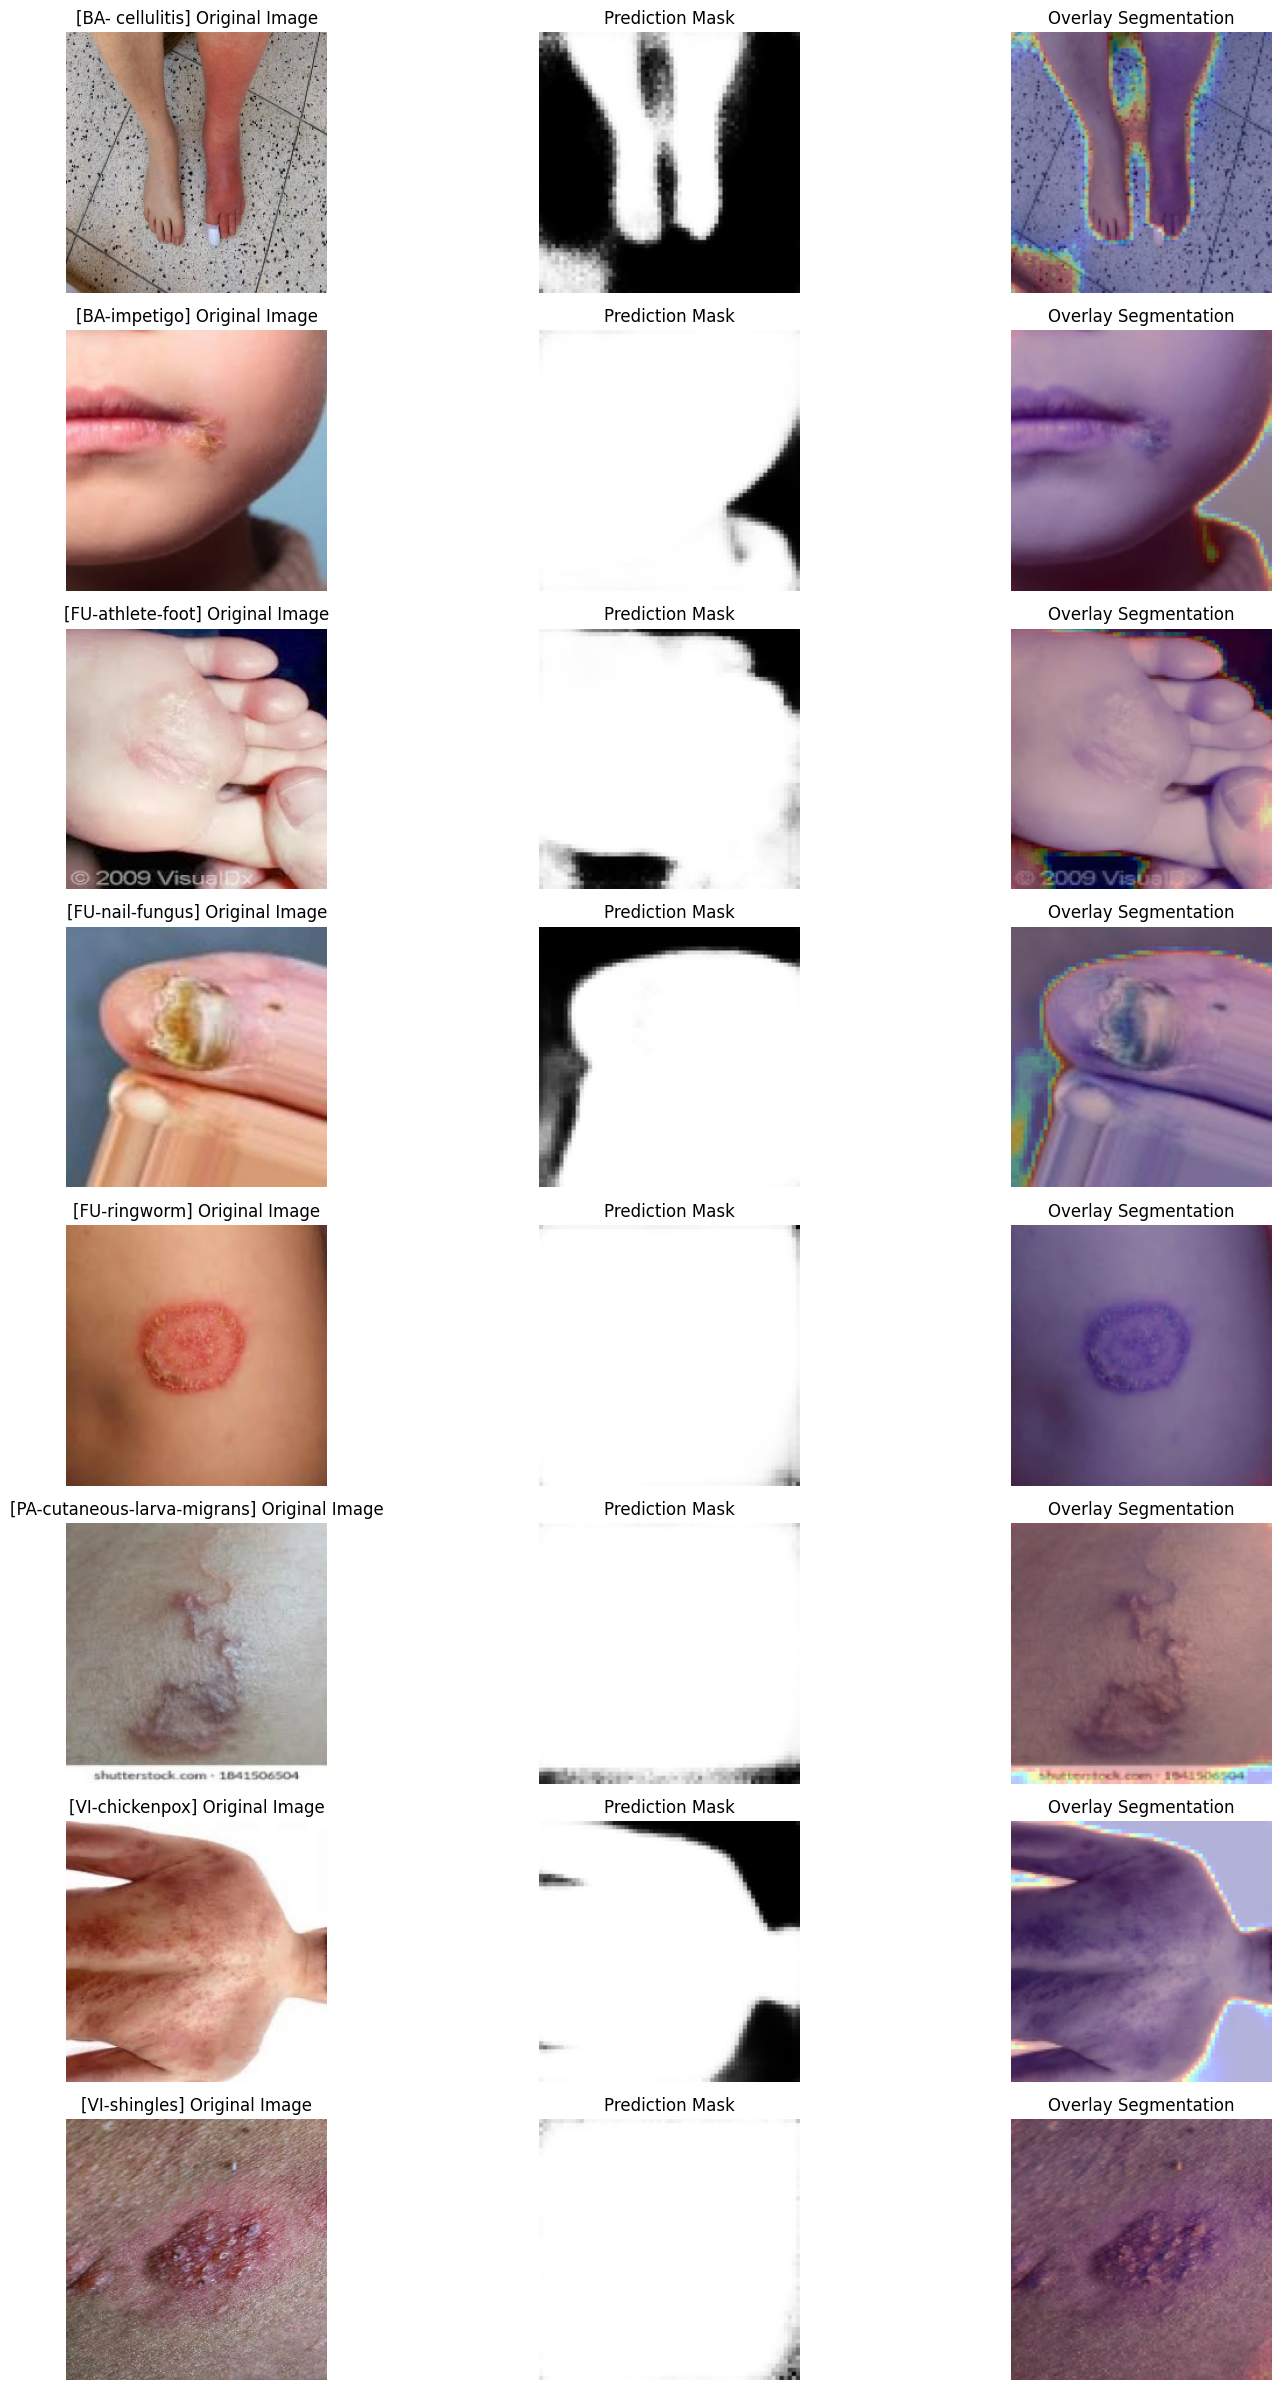

In [18]:
# ==================================================
# 6️⃣ ĐÁNH GIÁ MÔ HÌNH + HIỂN THỊ KẾT QUẢ PHÂN ĐOẠN
# ==================================================
import random
plt.figure(figsize=(16, len(sample_per_class) * 3))
i = 0
for class_name, img_path in sample_per_class.items():
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    resized_img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE)) / 255.0

    pred = model.predict(np.expand_dims(resized_img, axis=0))[0]
    pred_overlay = (pred.squeeze() * 255).astype(np.uint8)
    overlay_color = cv2.applyColorMap(pred_overlay, cv2.COLORMAP_JET)
    overlay_color = cv2.cvtColor(overlay_color, cv2.COLOR_BGR2RGB)
    blended = cv2.addWeighted((resized_img * 255).astype(np.uint8), 0.7, overlay_color, 0.3, 0)

    plt.subplot(len(sample_per_class), 3, i * 3 + 1)
    plt.imshow(img_rgb)
    plt.title(f"[{class_name}] Original Image")
    plt.axis("off")

    plt.subplot(len(sample_per_class), 3, i * 3 + 2)
    plt.imshow(pred.squeeze(), cmap='gray')
    plt.title("Prediction Mask")
    plt.axis("off")

    plt.subplot(len(sample_per_class), 3, i * 3 + 3)
    plt.imshow(blended)
    plt.title("Overlay Segmentation")
    plt.axis("off")

    i += 1

plt.tight_layout()
plt.show()

6/6 ━━━━━━━━━━━━━━━━━━━━ 41s 4s/step

===== FULL SEGMENTATION REPORT =====
Train: 684, Val: 172
Image Size: 128x128
Epochs: 30, Batch Size: 8
Training Time: 265.93 giây (4.43 phút)
Accuracy : 0.9410
Precision: 0.9538
Recall   : 0.9753
F1-score : 0.9644
Dice     : 0.9644
IoU      : 0.9313


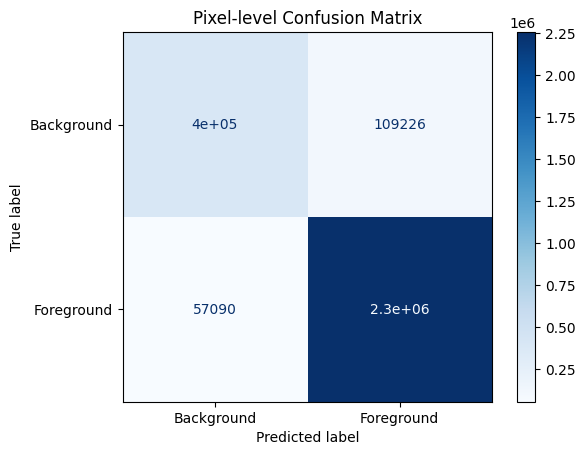

In [19]:
# ==================================================
# 7️⃣ FULL REPORT METRICS
# ==================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Dự đoán mask trên tập validation
Y_pred = model.predict(X_val)
Y_pred_bin = (Y_pred > 0.5).astype(np.uint8)

# Flatten và convert sang int
y_true_flat = (Y_val.flatten() > 0.5).astype(np.uint8)
y_pred_flat = (Y_pred_bin.flatten()).astype(np.uint8)


acc = accuracy_score(y_true_flat, y_pred_flat)
prec = precision_score(y_true_flat, y_pred_flat)
rec = recall_score(y_true_flat, y_pred_flat)
f1 = f1_score(y_true_flat, y_pred_flat)


# Dice & IoU
def dice_coef_np(y_true, y_pred, smooth=1e-6):
    intersection = np.sum(y_true * y_pred)
    return (2. * intersection + smooth) / (np.sum(y_true) + np.sum(y_pred) + smooth)

def iou_score_np(y_true, y_pred, smooth=1e-6):
    intersection = np.sum(y_true * y_pred)
    union = np.sum(y_true) + np.sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)

dice = dice_coef_np(y_true_flat, y_pred_flat)
iou = iou_score_np(y_true_flat, y_pred_flat)

# --- In báo cáo ---
print("\n===== FULL SEGMENTATION REPORT =====")
print(f"Train: {X_train.shape[0]}, Val: {X_val.shape[0]}")
print(f"Image Size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Epochs: {EPOCHS}, Batch Size: {BATCH_SIZE}")
print(f"Training Time: {train_time:.2f} giây ({train_time/60:.2f} phút)")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"Dice     : {dice:.4f}")
print(f"IoU      : {iou:.4f}")

# --- Confusion Matrix ---
cm = confusion_matrix(y_true_flat, y_pred_flat)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Background", "Foreground"])
disp.plot(cmap='Blues')
plt.title("Pixel-level Confusion Matrix")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step


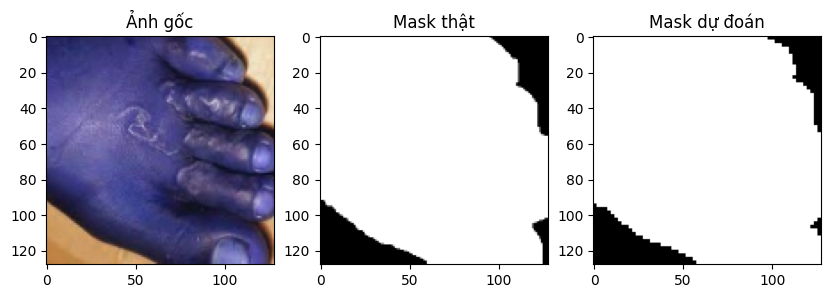

In [20]:
# ==================================================
# 🔍 DỰ ĐOÁN VÀ HIỂN THỊ MỘT ẢNH THỬ
# ==================================================
idx = random.randint(0, len(X_val) - 1)
test_img = X_val[idx]
true_mask = Y_val[idx]

pred_mask = model.predict(test_img[np.newaxis, ...])[0]
pred_mask = (pred_mask > 0.5).astype(np.uint8)

plt.figure(figsize=(10,4))
plt.subplot(1,3,1)
plt.imshow(test_img)
plt.title("Ảnh gốc")

plt.subplot(1,3,2)
plt.imshow(true_mask[...,0], cmap='gray')
plt.title("Mask thật")

plt.subplot(1,3,3)
plt.imshow(pred_mask[...,0], cmap='gray')
plt.title("Mask dự đoán")

plt.show()


🔎 Tìm thấy 233 ảnh để dự đoán.
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 293ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step


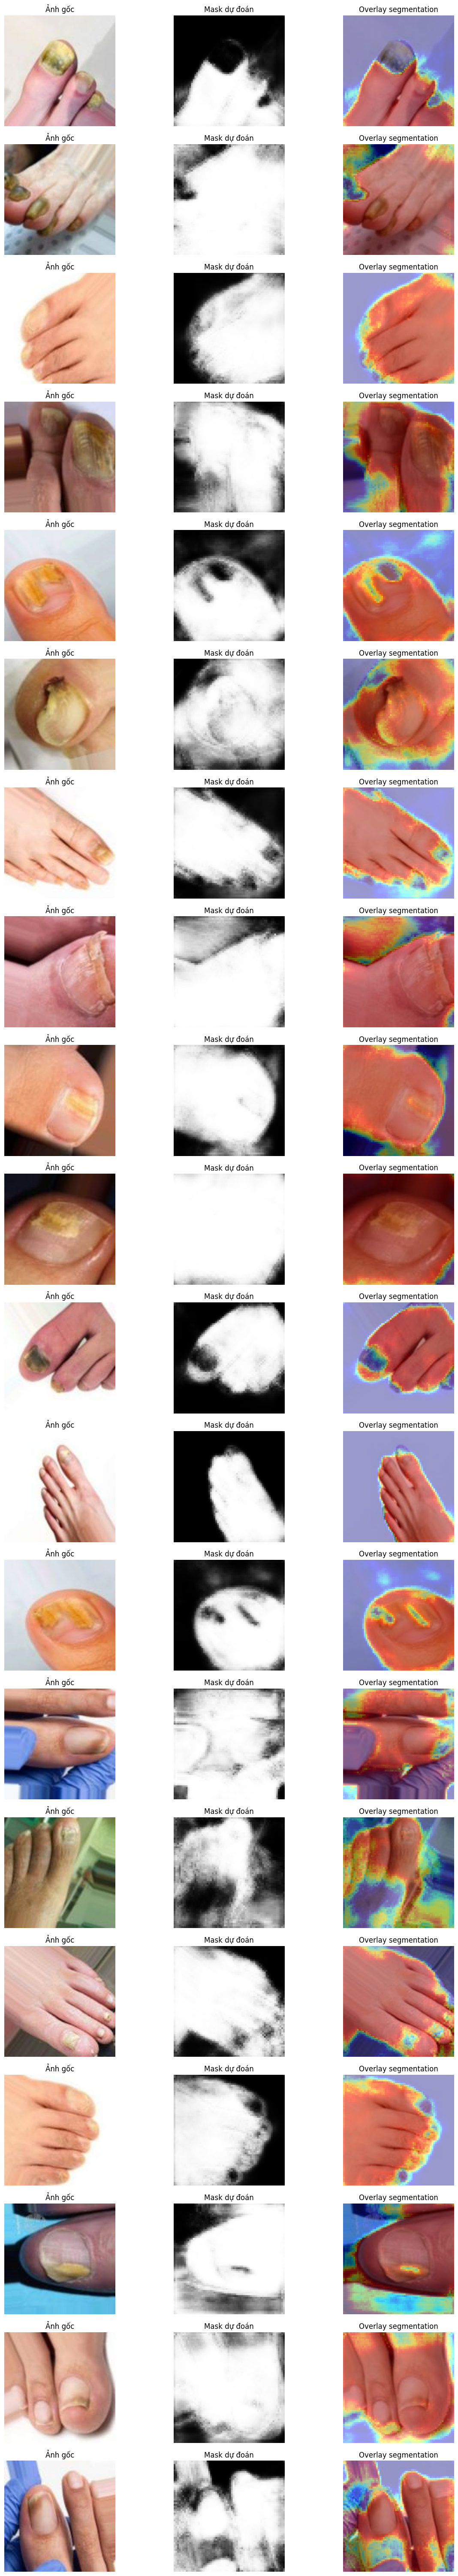

In [21]:
#========================================
# ==================================================
# 🔍 TEST TRÊN TẬP ẢNH KHÔNG CÓ MASK
# ==================================================

TEST_DIR = "/content/skin-disease-datasaet/test_set"
IMAGE_SIZE = 128

test_images = glob(os.path.join(TEST_DIR, "**", "*.*"), recursive=True)
test_images = [f for f in test_images if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

print(f"\n🔎 Tìm thấy {len(test_images)} ảnh để dự đoán.")

plt.figure(figsize=(12, len(test_images) * 3))

for i, img_path in enumerate(test_images[:20]):   # lấy 20 ảnh đầu → tránh quá nhiều
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    resized_img = cv2.resize(img_rgb, (IMAGE_SIZE, IMAGE_SIZE)) / 255.0

    # Dự đoán mask
    pred = model.predict(np.expand_dims(resized_img, axis=0))[0]
    pred_mask = (pred.squeeze() * 255).astype(np.uint8)

    # Overlay màu
    heatmap = cv2.applyColorMap(pred_mask, cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    blended = cv2.addWeighted((resized_img * 255).astype(np.uint8), 0.6, heatmap, 0.4, 0)

    # --- Hiển thị ---
    plt.subplot(len(test_images), 3, i * 3 + 1)
    plt.imshow(img_rgb)
    plt.title("Ảnh gốc")
    plt.axis("off")

    plt.subplot(len(test_images), 3, i * 3 + 2)
    plt.imshow(pred.squeeze(), cmap='gray')
    plt.title("Mask dự đoán")
    plt.axis("off")

    plt.subplot(len(test_images), 3, i * 3 + 3)
    plt.imshow(blended)
    plt.title("Overlay segmentation")
    plt.axis("off")

plt.tight_layout()
plt.show()